# ARTE4110U Week 1 Challenge: Train Linear Regression from Scratch

## Objective
Build a one-feature linear regression model without using a machine-learning library. You will implement the training loop, apply gradient descent, investigate the learning rate, report the loss, and visualize the best model against the data.

You are expected to complete the cells marked **TODO**. The notebook gives you the structure and mathematical guidance, but not the completed solution.

#### You have to do your research about the gradient calculations and training loop. This is the second challenge that would prepare you for the first Quiz of our ARTE4110 course. The quiz takes place after the second challenge.

#### Make sure to submit your complete notebook on Canvas by the due date.


## Rules and deliverables

- Use only Python, the libraries of NumPy and matplotlib, for the model, training loop, and plotting.
- Do not use `sklearn`, `numpy.polyfit`, or an optimizer such as `scipy.optimize`.
- Keep the five supplied data instances unchanged.
- Your final notebook must show the loss history, learning-rate comparison, and best-fit line.
- Add short written explanations wherever a prompt asks you to interpret a result.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.style.use('seaborn-v0_8-whitegrid')

## 1. Inspect the data

The model has one input feature and one output:
$$
[ \hat{y} = \phi_0 + \phi_1 x ]
$$

Here, `phi_0` is the intercept and `phi_1` is the slope.

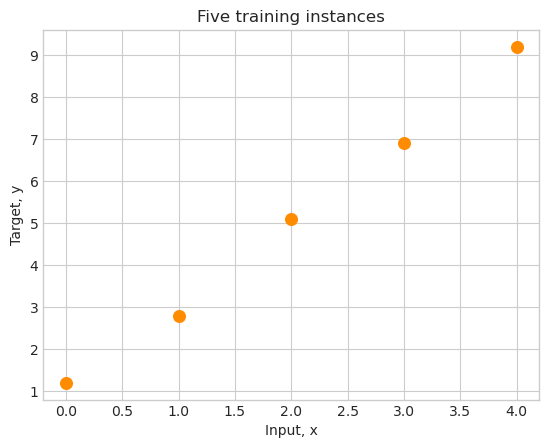

In [2]:
x = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
y = np.array([1.2, 2.8, 5.1, 6.9, 9.2])

assert x.shape == (5,) and y.shape == (5,)

plt.scatter(x, y, color='darkorange', s=70)
plt.xlabel('Input, x')
plt.ylabel('Target, y')
plt.title('Five training instances')
plt.show()

## 2. Define prediction and loss

Implement the prediction function and mean-squared error (MSE). Use the average over the five examples:

**TODO:** Complete both functions. Test them using any simple parameter values of your choice.

In [4]:
def predict(x, phi0, phi1):
    # TODO: return the predicted values for all x
    return phi0 + phi1 * x
    


def mse(y_true, y_pred):
    # TODO: return one scalar mean-squared error
    return np.mean((y_true - y_pred) ** 2)
    


# TODO: call your functions and inspect the result
print(predict(x, 1, 2))
print(mse(y, predict(x,1,2)))



[1. 3. 5. 7. 9.]
0.027999999999999924


## 3. Derive and implement the gradients

For the MSE above, compute the gradients. If you are not sure how, do you research and understand how it is computed.


**TODO:** Implement the two gradient expressions.

In [7]:
def gradients(x, y, phi0, phi1):
    # TODO: calculate predictions and residuals
    y_pred = predict(x, phi0, phi1)
    residuals = y_pred - y
    n = len(x)
    # TODO: calculate and return grad_phi0, grad_phi1
    grad_phi0 = (2/n) * np.sum(residuals)
    grad_phi1 = (2/n) * np.sum(x * residuals)

    return grad_phi0, grad_phi1


# TODO: evaluate the gradients at an initial parameter choice
grad_phi0, grad_phi1 = gradients(x, y, 0, 0)
print(grad_phi0)
print(grad_phi1)

-10.08
-28.200000000000003


## 4. Build the training loop

Use gradient descent when building the training loop.

Your function should record the loss after every update so that you can plot it later. Start with the same initial parameters for every experiment.

**TODO:** Complete the loop. Do not call a library optimizer.

In [8]:
def train(x, y, learning_rate, epochs, phi0_init=0.0, phi1_init=0.0):
    phi0 = phi0_init
    phi1 = phi1_init
    loss_history = []

    for epoch in range(epochs):
        # TODO: compute gradients
        grad_phi0, grad_phi1 = gradients(x, y, phi0, phi1)
        # TODO: update phi0 and phi1
        phi0 -= learning_rate * grad_phi0
        phi1 -= learning_rate * grad_phi1
        # TODO: calculate and append the current loss
        y_pred = predict(x, phi0, phi1)
        loss_history.append(mse(y, y_pred))
        

    return phi0, phi1, np.array(loss_history)


# TODO: train one model and print its final parameters and loss
phi0, phi1, loss_history = train(
    x, 
    y,
    learning_rate=0.01,
    epochs=1000
)
print("phi0", phi0)
print("phi1", phi1)
print("mse", loss_history[-1])

phi0 1.0192955494087588
phi1 2.010247107924661
mse 0.02620016632329958


## 5. Study the learning rate

The learning rate controls the size of each parameter update. Run the same training procedure with several learning rates.

Suggested values: `0.001`, `0.01`, `0.05`, and `0.2`. You may add another value if useful.

**TODO:**
1. Train one model for each learning rate.
2. Report the final loss and parameters.
3. Plot all loss histories on one figure.
4. Explain which learning rate you consider best and why. Discuss whether any rate is too slow, unstable, or converges well.

In [12]:
learning_rates = [0.001, 0.01, 0.05, 0.2]
epochs = 1000
results = {}

# TODO: fill results with parameters and loss histories for every learning rate
for lr in learning_rates:
    phi0, phi1, loss_history = train(
        x, y, lr, epochs
    )
    results[lr] = {
        "phi0": phi0,
        "phi1": phi1,
        "loss_history": loss_history
    }

# TODO: print a compact comparison table
print("Learning rate | phi0 | phi1 | mse")
for lr in learning_rates:
    phi0 = results[lr]["phi0"]
    phi1 = results[lr]["phi1"]
    final_loss = results[lr]["loss_history"][-1]

    print(f"{lr} | {phi0:.4f} | {phi1:.4f} | {final_loss:.6f}")


Learning rate | phi0 | phi1 | mse
0.001 | 0.8656 | 2.0641 | 0.034185
0.01 | 1.0193 | 2.0102 | 0.026200
0.05 | 1.0200 | 2.0100 | 0.026200
0.2 | -2186566201008448233264280382533615006405188335674392083575295093982073462519451652175349840119065876720757029420667974179771251394446158499382015761944210852965024221801761474717547476156847492626693906675108839863773915250688.0000 | -6233421510867725035689957023283202102236046556540067051568540283681896245282903134184805228778602672360411325411132354354440087886123335909015577708883797826708382315989490392071650269613301174593262482093511643770698841718784.0000 | inf


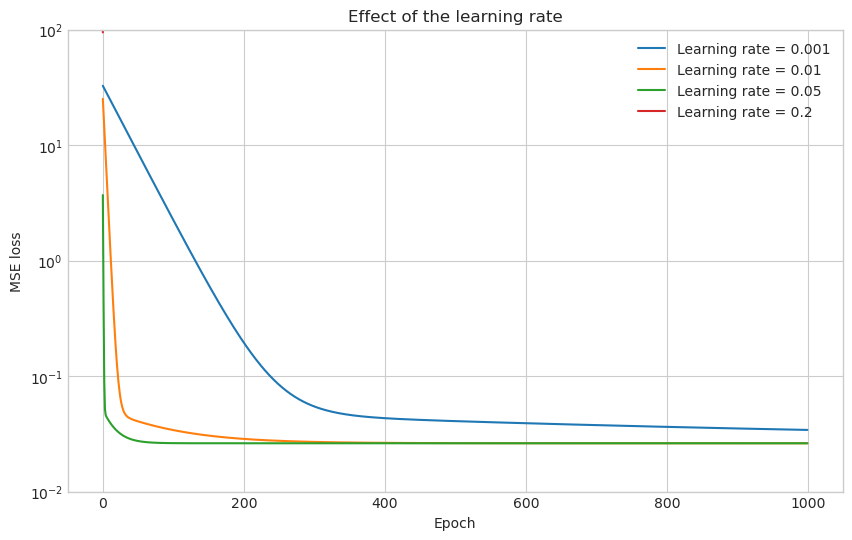

In [34]:
# TODO: plot the loss history for each learning rate
plt.figure(figsize=(10, 6))
for lr in learning_rates:
    loss_history = results[lr]["loss_history"]
    epoch_numbers = np.arange(len(loss_history))
    finite_mask = np.isfinite(loss_history)
    plt.plot(
        epoch_numbers[finite_mask],
        loss_history[finite_mask],
        label=f"Learning rate = {lr}"
    )
plt.yscale("log")
plt.ylim(0.01, 100)

plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.title('Effect of the learning rate')
plt.legend()
plt.show()

### Your interpretation

Write 3–5 sentences here. Refer to the shape of the curves and the final losses. If a curve behaves unexpectedly, suggest a reason.

ANS:

The learning rate of 0.001 converged slowly, reaching a final MSE of 0.034185 after 1,000 epochs. 

Learning rates of 0.01 and 0.05 both converged to approximately 0.0262, with 0.05 reaching the minimum loss faster. However, the learning rate of 0.2 caused the model to diverge, producing extremely large parameter values and an infinite loss due to numerical overflow. 

Based on the loss curves and convergence speed, 0.05 was the most effective learning rate for this dataset.


## 6. Plot the best model against the data

Select the learning rate that produced the most useful result. Plot the five data points and the line generated by your learned parameters.

**TODO:** Complete the plot. Label the axes, include a legend, and state the selected learning rate in the title or caption.

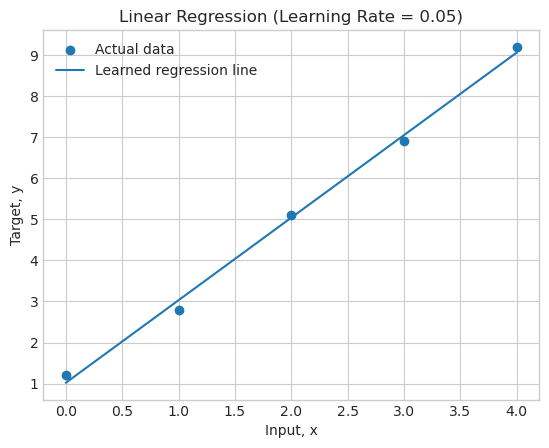

In [36]:
# TODO: choose the best learning rate based on your evidence
best_learning_rate = 0.05

# TODO: retrieve the corresponding learned parameters
phi0 = results[best_learning_rate]["phi0"]
phi1 = results[best_learning_rate]["phi1"]
# TODO: create a smooth set of x-values and predict the line
x_line = np.linspace(0, 4, 100)
y_line = predict(x_line, phi0, phi1)
# TODO: plot the data and the best model
plt.scatter(x, y, label="Actual data")
plt.plot(x_line, y_line, label="Learned regression line")

plt.xlabel("Input, x")
plt.ylabel("Target, y")
plt.title(f"Linear Regression (Learning Rate = {best_learning_rate})")
plt.legend()
plt.show()

## 7. Final reflection

Answer briefly:

1. What do the intercept and slope mean for this dataset?
2. Why does gradient descent need the negative gradient?
3. What is the trade-off between a very small and a very large learning rate?
4. How did you decide which model was the best?


1. Intercept represents the predicted value of y when x=0, the slop represents how much the value of y changes for every unit increase in x
2. Because it gives the direction of steepest local decrease in the loss, for a small learning rate, we can reduce the loss by moving in that direction
3. Speed and stability, because a very small learning rate produces smaller updates and may require more epochs to converge, while a very large learning rate can speed up the process but may overshoot the minimum loss and cause the model to diverge
4. By considering the MSE and the speed/stability of each model, for example 0.01 and 0.05 showed almost the same MSE, but 0.05 did it faster.

## Completion checklist

- [x] Prediction and MSE functions work.
- [x] Gradients are implemented from the provided formulas.
- [x] Training loop updates both parameters.
- [x] Loss is reported and decreases for at least one reasonable learning rate.
- [x] Learning rates are compared in a table and a plot.
- [x] The best model is plotted against all five data points.
- [x] Written interpretations are complete.